# AJQ ONET Merge model

In [33]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, recall_score, log_loss, confusion_matrix, ConfusionMatrixDisplay)

In [34]:
DATA_DIR = Path('../data')
if not (DATA_DIR / 'JFF_formatted_public_release_labels.csv').exists():
    DATA_DIR = Path('/mnt/data')
OUTPUT_DIR = DATA_DIR / 'ajq_onet_outputs'
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
SEED = 1234

In [35]:
# Load the respondent-level AJQ survey and occupation-level O*NET Work Values table.
df = pd.read_csv(DATA_DIR / 'JFF_formatted_public_release_labels.csv', encoding='latin1', low_memory=False)
wv_raw = pd.read_excel(DATA_DIR / 'Work Values.xlsx')

print('AJQ rows/columns:', df.shape)
print('O*NET raw rows/columns:', wv_raw.shape)

AJQ rows/columns: (18429, 153)
O*NET raw rows/columns: (7866, 9)


In [36]:
# Convert Q4 (overall job satisfaction) into a number from 0 through 10.
df_clean = df.copy()
df_clean['Q4_Numeric'] = pd.to_numeric(
    df_clean['Q4'].astype(str).str.extract(r'^(\d+)')[0], errors='coerce'
)

# Create the binary classification label
# 1 means highly satisfied (8–10); 0 means not highly satisfied (0–7).
df_clean = df_clean.loc[df_clean['Q4_Numeric'].between(0, 10)].copy()
df_clean['Highly_Satisfied'] = (df_clean['Q4_Numeric'] >= 8).astype(int)

print('Valid respondents:', len(df_clean))
print('Positive class proportion:', round(df_clean['Highly_Satisfied'].mean(), 3))

Valid respondents: 18381
Positive class proportion: 0.416


In [37]:
# O*NET uses different measurement scales; EX means Extent (how characteristic the work value is of the occupation).
work_value_cols = ['Achievement', 'Independence', 'Recognition','Relationships', 
                   'Support', 'Working Conditions']

wv_ex = wv_raw.loc[wv_raw['Scale ID'].eq('EX')].copy()

# Pivot from long format to wide format: one row per detailed O*NET occupation and one column per work value.
df_onet = wv_ex.pivot_table(
    index=['O*NET-SOC Code', 'Title'], columns='Element Name',
    values='Data Value', aggfunc='mean'
).reset_index()
df_onet.columns.name = None

# Extract portions of the SOC code so detailed occupations can be aggregated to broad groups compatible with AJQ Q6.
assert all(c in df_onet for c in work_value_cols)
df_onet['SOC_2Digit'] = df_onet['O*NET-SOC Code'].astype(str).str[:2]
df_onet['SOC_3Digit'] = df_onet['O*NET-SOC Code'].astype(str).str[:4]

assert df_onet['O*NET-SOC Code'].is_unique
print('Detailed O*NET occupations:', len(df_onet))

Detailed O*NET occupations: 874


In [38]:
# Define a dictionary from two-digit SOC major groups to AJQ Q6 labels.
# The healthcare-technicians exception uses SOC 29-2 as a rough subgroup; the category is still not an exact individual job match.
soc_to_ajq = {
    '11':'Management', '13':'Business and financial operations',
    '15':'Computer and mathematical', '17':'Architecture and engineering',
    '19':'Life, physical, and social science', '21':'Community and social service',
    '23':'Legal', '25':'Educational instruction and library',
    '27':'Arts, design, entertainment, sports, and media',
    '29':'Healthcare practitioners', '31':'Healthcare support',
    '33':'Protective service', '35':'Food preparation and service',
    '37':'Building and grounds cleaning and maintenance',
    '39':'Personal care and service', '41':'Sales and related',
    '43':'Office and administrative support',
    '45':'Farming, fishing, and forestry', '47':'Construction and extraction',
    '49':'Installation, maintenance, and repair', '51':'Production',
    '53':'Transportation and material moving'
}

# NOTE: Missing Q6, "Something else", and Military remain unmatched.
df_onet['AJQ_Category'] = df_onet['SOC_2Digit'].map(soc_to_ajq)
df_onet.loc[df_onet['SOC_3Digit'].eq('29-2'), 'AJQ_Category'] = 'Healthcare technicians'


In [39]:
# Aggregate individual O*NET occupations into a single average work-value profile for each AJQ occupation group.
df_onet_aggregated = (
    df_onet.dropna(subset=['AJQ_Category'])
    .groupby('AJQ_Category', as_index=False)[work_value_cols].mean()
)

# Count the O*NET occupations within each group to show how broad its average is.
counts = (df_onet.dropna(subset=['AJQ_Category'])
          .groupby('AJQ_Category')['O*NET-SOC Code']
          .nunique().rename('onet_occupation_count').reset_index())

df_onet_aggregated = df_onet_aggregated.merge(counts, on='AJQ_Category', validate='one_to_one')

# Prefix O*NET predictor names to prevent collisions with AJQ survey fields.
onet_feature_names = ['ONET_' + v.replace(' ', '_') for v in work_value_cols]
df_onet_aggregated = df_onet_aggregated.rename(columns=dict(zip(work_value_cols, onet_feature_names)))

# Merge without filtering on Q6
df_merged = df_clean.merge(
    df_onet_aggregated, how='left', left_on='Q6', right_on='AJQ_Category',
    validate='many_to_one', indicator='merge_status'
)
assert len(df_merged) == len(df_clean), 'Unexpected row multiplication during merge!'

# Rename O*NET columns with ONET_ prefixes so they are unambiguous after merging.
# Use a left join so each AJQ respondent remains in the dataset
df_merged['onet_matched'] = df_merged[onet_feature_names].notna().all(axis=1)
df_merged['match_level'] = np.where(df_merged['onet_matched'], 'SOC group aggregate', 'Unmatched')

# Flag unmatched respondents, inspect coverage, then save the merged data and occupation-level crosswalk.
print('Merged rows:', len(df_merged))
print('Match rate:', f"{df_merged['onet_matched'].mean():.2%}")
print('Unmatched Q6 categories:')
print(df_merged.loc[~df_merged['onet_matched'], 'Q6'].value_counts(dropna=False).to_string())
print('\nOccupational crosswalk coverage:')

display(df_onet_aggregated[['AJQ_Category','onet_occupation_count']].sort_values('AJQ_Category'))

# Preserve the original survey columns AND occupational estimates for later analysis.
df_merged.to_csv(OUTPUT_DIR / 'ajq_onet_merged.csv', index=False)
df_onet_aggregated.to_csv(OUTPUT_DIR / 'ajq_onet_crosswalk_aggregates.csv', index=False)

Merged rows: 18381
Match rate: 99.38%
Unmatched Q6 categories:
Q6
Something else (please specify):    65
Military                            32
No response                         17

Occupational crosswalk coverage:


,AJQ_Category,onet_occupation_count
0,Architecture and engineering,55
1,"Arts, design, entertainment, sports, and media",38
2,Building and grounds cleaning and maintenance,8
3,Business and financial operations,43
4,Community and social service,14
5,Computer and mathematical,29
6,Construction and extraction,61
7,Educational instruction and library,57
8,"Farming, fishing, and forestry",12
9,Food preparation and service,16


In [47]:
# Create a crosswalk containing every AJQ occupation category
ajq_crosswalk = pd.DataFrame({
    "AJQ_Q6": df["Q6"].dropna().unique()
})

# Attach the corresponding O*NET aggregate information
ajq_crosswalk = ajq_crosswalk.merge(df_onet_aggregated, left_on="AJQ_Q6", right_on="AJQ_Category",
    how="left", validate="one_to_one"
)

# Classify the level of occupational matching
ajq_crosswalk["match_type"] = np.where(ajq_crosswalk["AJQ_Category"].notna(), "aggregate", "unmapped")

# Display the crosswalk
display(ajq_crosswalk[ ["AJQ_Q6", "AJQ_Category", "match_type", "onet_occupation_count"]].sort_values("AJQ_Q6")
)

# Save the crosswalk
ajq_crosswalk.to_csv(OUTPUT_DIR / "ajq_onet_crosswalk.csv", index=False)

,AJQ_Q6,AJQ_Category,match_type,onet_occupation_count
17,Architecture and engineering,Architecture and engineering,aggregate,55.0
20,"Arts, design, entertainment, sports, and media","Arts, design, entertainment, sports, and media",aggregate,38.0
0,Building and grounds cleaning and maintenance,Building and grounds cleaning and maintenance,aggregate,8.0
1,Business and financial operations,Business and financial operations,aggregate,43.0
21,Community and social service,Community and social service,aggregate,14.0
2,Computer and mathematical,Computer and mathematical,aggregate,29.0
3,Construction and extraction,Construction and extraction,aggregate,61.0
8,Educational instruction and library,Educational instruction and library,aggregate,57.0
25,"Farming, fishing, and forestry","Farming, fishing, and forestry",aggregate,12.0
18,Food preparation and service,Food preparation and service,aggregate,16.0


In [40]:
# Define the demographic/employment baseline, AJQ workplace-quality variables, and five controlled model comparisons
baseline_features = [
    'Q20','Q40','Q14','Q65','Q9','Q8','Q17',
    'MARITAL_STATUS','EDUCATION','Q51','REGION'
]

job_quality_features = [
    'Q33A','Q33B','Q33C','Q33D','Q33E',
    'Q33F','Q33G','Q33H','Q33I','Q33J','Q55'
]

# Use Q6 only in the occupation-control model to test whether broad occupational membership explains any apparent O*NET benefit.
model_features = {
    'Baseline': baseline_features,
    'AJQ Job Quality': baseline_features + job_quality_features,
    'Baseline + O*NET': baseline_features + onet_feature_names,
    'AJQ + O*NET Combined': baseline_features + job_quality_features + onet_feature_names,
    'Occupation Control (Q6)': baseline_features + job_quality_features + ['Q6']
}

# Deduplicate feature names before selecting columns to prevent duplicate one-hot columns.
model_features = {name: list(dict.fromkeys(features)) for name, features in model_features.items()}
required = set(sum(model_features.values(), []))
missing = sorted(required - set(df_merged.columns))

if missing:
    raise KeyError(f'Missing required AJQ/O*NET columns: {missing}')

# Clean survey nonresponse labels in predictor columns (not target).
# Convert survey nonresponse labels to missing values and parse numeric fields.
all_features = list(dict.fromkeys(sum(model_features.values(), [])))
X_all = df_merged[all_features].copy()
X_all = X_all.replace(r'^\s*$', np.nan, regex=True)
X_all = X_all.replace(['No response', 'Not sure', 'Not applicable'], np.nan)
X_all['Q20'] = pd.to_numeric(X_all['Q20'], errors='coerce')
X_all['Q17'] = pd.to_numeric(X_all['Q17'].astype(str).str.extract(r'^(\d+)')[0], errors='coerce')
X_all['Q51'] = pd.to_numeric(X_all['Q51'], errors='coerce')

for col in onet_feature_names:
    X_all[col] = pd.to_numeric(X_all[col], errors='coerce')
    
# Make one stratified train/test split and reuse its row indices for every model
y = df_merged['Highly_Satisfied']
train_idx, test_idx = train_test_split(
    np.arange(len(df_merged)), test_size=0.33, random_state=SEED, stratify=y
)

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

In [42]:
def preprocess_features(X_train_raw, X_test_raw, features):
    # Select only the requested model feature group, then divide columns into numeric and categorical predictors.
    X_train = X_train_raw[features].copy()
    X_test = X_test_raw[features].copy()
    numeric_cols = [c for c in ['Q20', 'Q17', 'Q51'] + onet_feature_names if c in features]
    categorical_cols = [c for c in features if c not in numeric_cols]

    # Impute medians using the training split only to avoid information leaking from the test split.
    for col in numeric_cols:
        median_value = X_train[col].median()
        if pd.isna(median_value):
            median_value = 0.0
        X_train[col] = X_train[col].fillna(median_value)
        X_test[col] = X_test[col].fillna(median_value)

    # Replace missing categories with a Missing label
    for col in categorical_cols:
        X_train[col] = X_train[col].astype('object').fillna('Missing').astype(str)
        X_test[col] = X_test[col].astype('object').fillna('Missing').astype(str)
        
    # Full one-hot encoding avoids inconsistent reference-category omission across splits.
    X_train = pd.get_dummies(X_train, columns=categorical_cols, drop_first=False, dtype=float)

    # Align test indicator columns to the trained column set, then save names before scaling removes DataFrame metadata.
    X_test = pd.get_dummies(X_test, columns=categorical_cols, drop_first=False, dtype=float)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
    assert X_train.columns.is_unique

    feature_names = X_train.columns.tolist()

    # Fit the scaler on training rows, applying the same means and standard deviations to test rows.
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    return X_train_scaled, X_test_scaled, feature_names

In [43]:
# The training function fits ONE logistic regression model and returns both evaluation metrics and the fitted estimator.
# ROC-AUC and log loss use predicted probabilities, while accuracy/F1/recall use predicted class labels.
def train_test_LR(X_train, y_train, X_test, y_test, c=1):
    model = LogisticRegression(C=c, max_iter=2000, random_state=42)
    model.fit(X_train, y_train)
    
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)
    
    return {
        'model': model,
        'accuracy': accuracy_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_prob),
        'f1': f1_score(y_test, y_pred, zero_division=0),
        'recall': recall_score(y_test, y_pred, zero_division=0),
        'log_loss': log_loss(y_test, y_prob),
        'predictions': y_pred,
        'probabilities': y_prob
    }

# Loop through all five feature sets on the same respondents; each model is fitted exactly once.
results = {}
for name, features in model_features.items():
    X_train, X_test, feature_names = preprocess_features(
        X_all.iloc[train_idx], X_all.iloc[test_idx], features
    )
    result = train_test_LR(X_train, y_train, X_test, y_test)
    result['feature_names'] = feature_names
    results[name] = result
    print(f"{name}: accuracy={result['accuracy']:.4f}, AUC={result['roc_auc']:.4f}, "
          f"F1={result['f1']:.4f}")

# Save a comparison table so results can be used in a presentation or shared with teammates.
comparison = pd.DataFrame([
    {'Model': name, 'Accuracy': r['accuracy'], 'ROC-AUC': r['roc_auc'],
     'F1 Score': r['f1'], 'Recall': r['recall'], 'Log Loss': r['log_loss']}
    for name, r in results.items()
]).set_index('Model')
display(comparison.round(4))

comparison.to_csv(OUTPUT_DIR / 'ajq_onet_model_comparison.csv')

Baseline: accuracy=0.6274, AUC=0.6532, F1=0.4562
AJQ Job Quality: accuracy=0.7572, AUC=0.8307, F1=0.7069
Baseline + O*NET: accuracy=0.6325, AUC=0.6538, F1=0.4648
AJQ + O*NET Combined: accuracy=0.7554, AUC=0.8304, F1=0.7047
Occupation Control (Q6): accuracy=0.7587, AUC=0.8306, F1=0.7103


,Accuracy,ROC-AUC,F1 Score,Recall,Log Loss
Model,,,,,
Baseline,0.6274,0.6532,0.4562,0.3757,0.6432
AJQ Job Quality,0.7572,0.8307,0.7069,0.7039,0.4974
Baseline + O*NET,0.6325,0.6538,0.4648,0.3837,0.6428
AJQ + O*NET Combined,0.7554,0.8304,0.7047,0.7019,0.4977
Occupation Control (Q6),0.7587,0.8306,0.7103,0.7115,0.4977


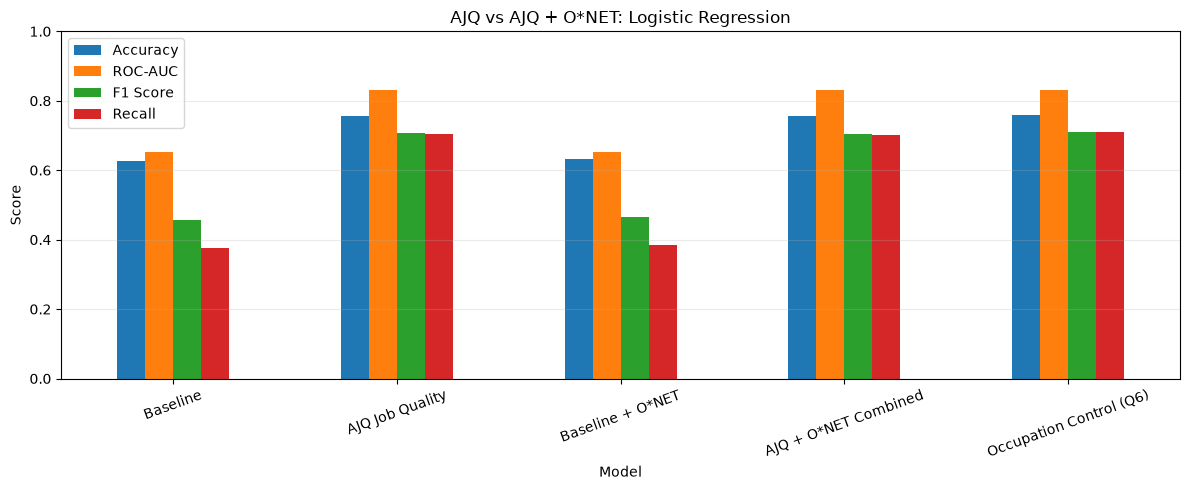

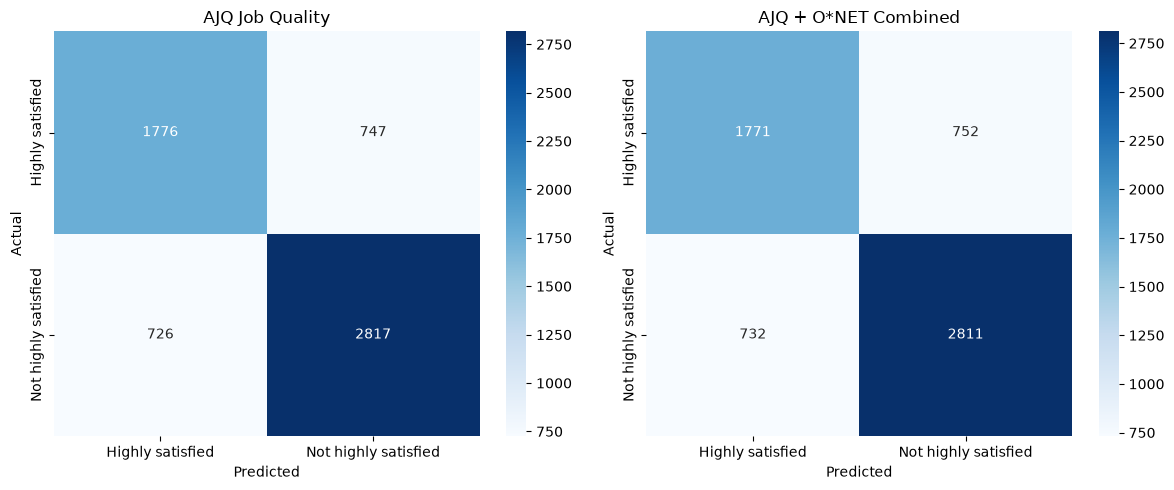

In [44]:
# Compare all models on four higher-is-better classification metrics.
comparison[['Accuracy', 'ROC-AUC', 'F1 Score', 'Recall']].plot(kind='bar', figsize=(12,5), rot=20)

# Plot the confusion matrices for AJQ job quality alone versus the combined AJQ + O*NET model.
plt.title('AJQ vs AJQ + O*NET: Logistic Regression')
plt.ylabel('Score'); plt.ylim(0,1); plt.grid(axis='y', alpha=.25)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12,5))
for ax, name in zip(axes, ['AJQ Job Quality', 'AJQ + O*NET Combined']):
    cm = confusion_matrix(y_test, results[name]['predictions'], labels=[1,0])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Highly satisfied', 'Not highly satisfied'],
                yticklabels=['Highly satisfied', 'Not highly satisfied'])
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

,Feature,Coefficient,Absolute_Coefficient
101,Q33G_Strongly agree,0.405905,0.405905
102,Q33G_Strongly disagree,-0.333997,0.333997
100,Q33G_Somewhat disagree,-0.276475,0.276475
2,Q51,0.273720,0.273720
113,Q33I_Strongly agree,0.241794,0.241794


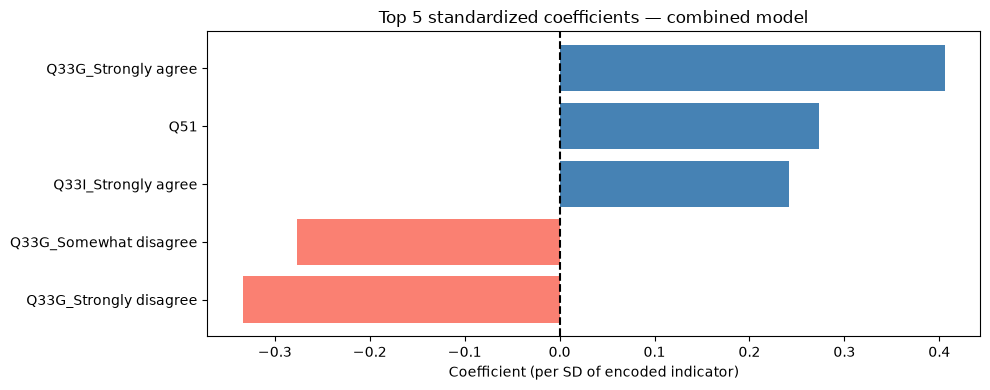

In [45]:
# Access the fitted combined model from results
combined = results['AJQ + O*NET Combined']
coef_df = pd.DataFrame({
    'Feature': combined['feature_names'],
    'Coefficient': combined['model'].coef_[0]
})

# Each coefficient corresponds to a transformed (often one-hot-encoded) feature and represents a change in predicted log-odds.
coef_df['Absolute_Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values('Absolute_Coefficient', ascending=False)

# Rank top 5 influential features
top_5 = coef_df.head(5)
display(top_5)
coef_df.to_csv(OUTPUT_DIR / 'ajq_onet_combined_coefficients.csv', index=False)

# Print eda of top 5 features
plot_df = top_5.sort_values('Coefficient')
plt.figure(figsize=(10, 4))
plt.barh(plot_df['Feature'], plot_df['Coefficient'],
         color=['steelblue' if v >= 0 else 'salmon' for v in plot_df['Coefficient']])
plt.axvline(0, color='black', linestyle='--')
plt.title('Top 5 standardized coefficients — combined model')
plt.xlabel('Coefficient (per SD of encoded indicator)')
plt.tight_layout(); plt.show()

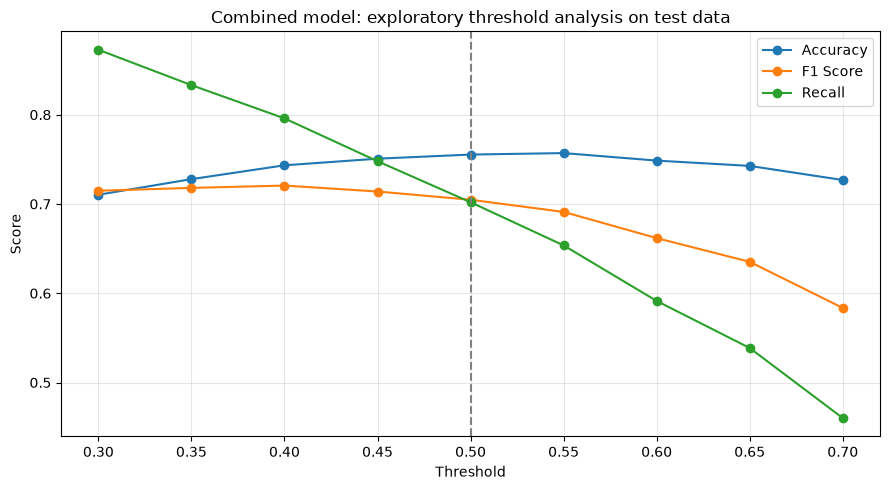

In [46]:
# Use already-computed class probabilities to plot how the classification threshold changes accuracy, F1, and recall.
y_prob = combined['probabilities']

thresholds = np.arange(.30, .71, .05)
threshold_scores = []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)
    threshold_scores.append({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred)
    })
    
threshold_df = pd.DataFrame(threshold_scores)
threshold_df.set_index('Threshold').plot(marker='o', figsize=(9,5))


plt.axvline(.5, linestyle='--', color='gray', label='Default: 0.50')
plt.title('Combined model: exploratory threshold analysis on test data')
plt.ylabel('Score'); plt.grid(True, alpha=.3)
plt.tight_layout(); plt.show()